In [ ]:
# import dataset

import kagglehub
paultimothymooney_chest_xray_pneumonia_path = kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia')

print('Data source import complete.')

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Data source import complete.


In [ ]:
# import libraries

import os
import re
import cv2
import time
import shutil
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt
import tensorflow.keras.backend as K
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score,
    f1_score
)
from tqdm import tqdm
from tensorflow.keras import layers
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split, KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from sklearn.utils import shuffle
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization,
    Activation
)

{'NORMAL': 1583, 'PNEUMONIA': 4273} 



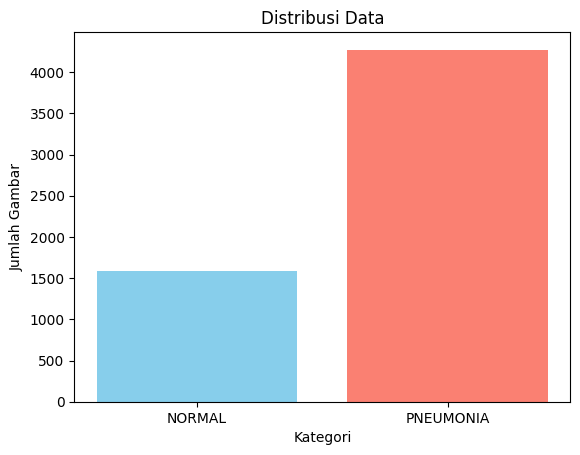

In [ ]:
# directory access

dir = '/kaggle/input/chest-xray-pneumonia/'

categories = ["NORMAL", "PNEUMONIA"]
counts = {}
img_size = 150

data = []

for category in categories:
    train = os.path.join(dir, 'chest_xray', 'train', category)
    test = os.path.join(dir, 'chest_xray', 'test', category)
    val = os.path.join(dir, 'chest_xray', 'val', category)
    counts[category] = len(os.listdir(train)) + len(os.listdir(test)) + len(os.listdir(val))
    class_num = categories.index(category)

print(counts, "\n")

plt.bar(counts.keys(), counts.values(), color=['skyblue', 'salmon'])
plt.title("Distribusi Data")
plt.xlabel("Kategori")
plt.ylabel("Jumlah Gambar")
plt.show()

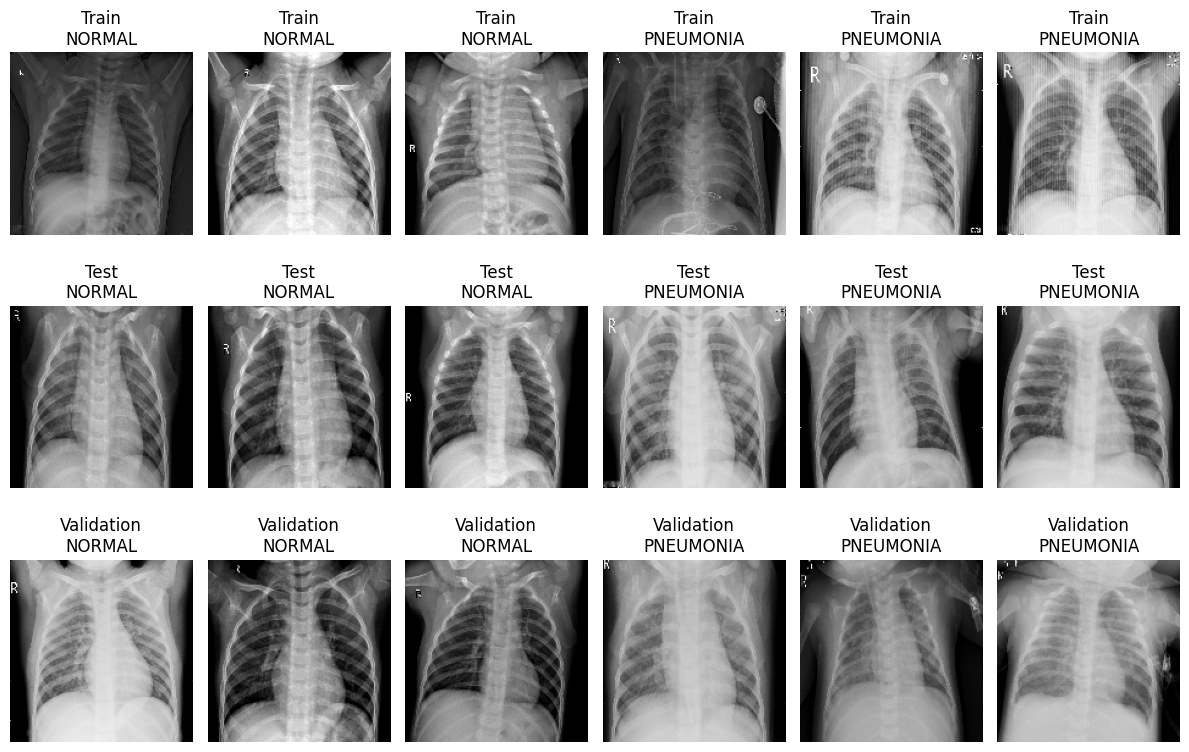

In [ ]:
# preprocessing image visualization

def load_preprocessed_samples(data_dir, samples_per_class=3):
    data = []
    for category in categories:
        path = os.path.join(data_dir, category)
        class_num = categories.index(category)
        for img_name in os.listdir(path)[:samples_per_class]:
            img_path = os.path.join(path, img_name)

            img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

            resized_img = cv2.resize(img_array, (img_size, img_size))

            normalized_img = resized_img / 255.0

            data.append((normalized_img, class_num, category))
    return data

train_samples = load_preprocessed_samples(os.path.join(dir, "chest_xray", "train"))
test_samples  = load_preprocessed_samples(os.path.join(dir, "chest_xray", "test"))
val_samples   = load_preprocessed_samples(os.path.join(dir, "chest_xray", "val"))

plt.figure(figsize=(12, 8))

all_samples = [("Train", train_samples), ("Test", test_samples), ("Validation", val_samples)]

for i, (split_name, samples) in enumerate(all_samples):
    for j, (img, label, category) in enumerate(samples):
        plt.subplot(len(all_samples), len(samples), i*len(samples)+j+1)
        plt.imshow(img, cmap="gray")
        plt.title(f"{split_name}\n{category}")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def prepare_data(samples):
    X = []
    y = []
    for img, label, _ in samples:
        X.append(img)
        y.append(label)
    X = np.array(X).reshape(-1, img_size, img_size, 1)
    y = to_categorical(y, num_classes=len(categories))
    return X, y

In [ ]:
X_train, y_train = prepare_data(train_samples)
X_test, y_test = prepare_data(test_samples)
X_val, y_val = prepare_data(val_samples)

In [ ]:
X_train, y_train = shuffle(X_train, y_train, random_state=42)

In [ ]:
# CNN modeling

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(img_size, img_size, 1)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(categories), activation='softmax')
])
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,034 (18.42 MB)

 Trainable params: 4,828,034 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# train model

history = model.fit(X_train, y_train,
                    epochs=10,
                    batch_size=32,
                    validation_data=(X_val, y_val))

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 0.6964 - val_accuracy: 0.5000 - val_loss: 0.7079
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 786ms/step - accuracy: 0.6667 - loss: 0.7912 - val_accuracy: 0.5000 - val_loss: 0.7542
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step - accuracy: 0.5000 - loss: 0.6920 - val_accuracy: 0.5000 - val_loss: 0.7545
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.5000 - loss: 0.6830 - val_accuracy: 0.5000 - val_loss: 0.7105
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.3333 - loss: 0.7029 - val_accuracy: 0.5000 - val_loss: 0.6999
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 697ms/step - accuracy: 0.6667 - loss: 0.6416 - val_accuracy: 0.3333 - val_loss: 0.6955
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 584ms/step - accuracy: 0.8333 - loss: 0.6715 - val_accuracy: 0.5000 - val_loss: 0.6921
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.8333 - loss: 0.6274 - val_accuracy: 0.5000 - val_loss: 0.

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5000 - loss: 0.6495
Test accuracy: 0.5000


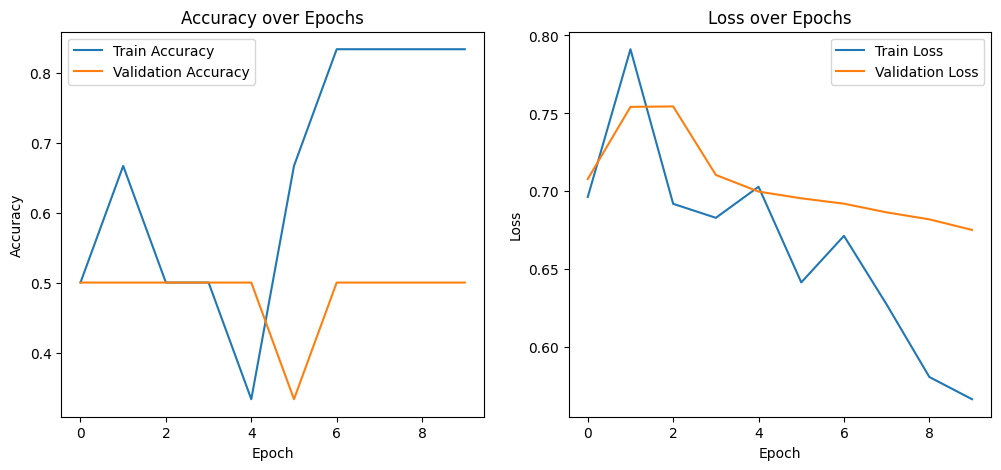

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [ ]:
train_acc = history.history['accuracy'][-1] * 100

val_acc = history.history['val_accuracy'][-1] * 100

test_loss, test_acc = model.evaluate(X_test, y_test)
test_acc_percent = test_acc * 100

print(f"Training Accuracy: {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Test Accuracy: {test_acc_percent:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5000 - loss: 0.6495
Training Accuracy: 83.33%
Validation Accuracy: 50.00%
Test Accuracy: 50.00%
